# Machine Learning — Home Assignment
**The Machine Learning Process**

- **Task A:** Airline Passenger Satisfaction (classification)
- **Task B:** NYC Taxi Trip Duration (regression)

Name: Olyad Bizuneh

This notebook reproduces the whole assignment from start to finish: EDA, cleaning, feature engineering, splitting, baseline models, hyperparameter tuning, final testing, saving the models, a deployment demo and monitoring.
It writes the same files as the scripts in `src/` (`reports/figures/*.png`, `reports/*_metrics.json`, `models/*.joblib`), so the report, the Streamlit app and the FastAPI service all use what this notebook produces.

**Runtime:** about 35 minutes on a laptop in total (airline ≈ 6 min, taxi ≈ 25 min, most of it spent on hyperparameter search).
**Data:** `data/airline/train.csv`, `data/airline/test.csv` (Kaggle *teejmahal20/airline-passenger-satisfaction*) and `data/taxi/NYC.csv` (Kaggle *NYC Taxi Trip Duration*).

## 0. Setup

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from lightgbm import LGBMClassifier, LGBMRegressor, early_stopping
from scipy.stats import loguniform, randint, uniform
from sklearn.cluster import MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
                             f1_score, mean_absolute_error, mean_squared_error, precision_score, r2_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, StratifiedKFold,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

%matplotlib inline
warnings.filterwarnings("ignore", category=UserWarning)

# Project root = folder that contains data/ (works whether the notebook is run from notebooks/ or the root)
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG, MODELS, REPORTS = ROOT / "reports" / "figures", ROOT / "models", ROOT / "reports"
for d in (FIG, MODELS):
    d.mkdir(parents=True, exist_ok=True)
sys.path[:0] = [str(ROOT), str(ROOT / "src")]

SEED = 42
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 50)


def save(fig, name):
    """Save a figure for the report and show it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150)
    plt.show()


def r4(d):
    return {k: round(float(v), 4) for k, v in d.items()}


print("Project root:", ROOT)

Project root: C:\Users\aaa\Desktop\olyad_assignment


---
# Task A — Airline Passenger Satisfaction (classification)

## 1. Problem definition
Predict whether a passenger is **satisfied** (1) or **neutral / dissatisfied** (0) from their profile, flight details, 14 service ratings (0–5) and delays.

- **Primary metrics:** F1-score and ROC-AUC (plus accuracy, precision and recall)
- **Success criteria:** test accuracy ≥ 95 %, F1 ≥ 0.94, ROC-AUC ≥ 0.98, train–validation gap < 2 points

## 2. Data collection

In [2]:
SERVICE_COLS = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
                "Gate location", "Food and drink", "Online boarding", "Seat comfort",
                "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
                "Checkin service", "Inflight service", "Cleanliness"]
CAT_COLS = ["Gender", "Customer Type", "Type of Travel", "Class"]
NUM_BASE = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
ENGINEERED = ["service_mean", "service_min", "low_scores", "total_delay", "delay_gained", "log_distance"]
NUM_COLS = NUM_BASE + SERVICE_COLS + ENGINEERED
TARGET = "satisfied"

t0_air = time.time()
air_report = {"project": "Airline Passenger Satisfaction (classification)"}

air_train_raw = pd.read_csv(ROOT / "data" / "airline" / "train.csv")
air_test_raw = pd.read_csv(ROOT / "data" / "airline" / "test.csv")
for df in (air_train_raw, air_test_raw):
    df.drop(columns=[c for c in ["Unnamed: 0", "id"] if c in df.columns], inplace=True)
    df[TARGET] = (df.pop("satisfaction") == "satisfied").astype(int)

print("train:", air_train_raw.shape, " test:", air_test_raw.shape)
air_train_raw.head()

train: (103904, 23)  test: (25976, 23)


C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\274841693.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[c for c in ["Unnamed: 0", "id"] if c in df.columns], inplace=True)
C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\274841693.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[c for c in ["Unnamed: 0", "id"] if c in df.columns], inplace=True)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfied
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,0
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,0
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,1
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,0
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,1


## 3. Data exploration and preparation
### 3.1 Exploratory data analysis

In [3]:
air_all = pd.concat([air_train_raw, air_test_raw], ignore_index=True)
eda = air_report.setdefault("eda", {})
eda["rows"], eda["cols"] = int(air_all.shape[0]), int(air_all.shape[1])
eda["missing"] = {k: int(v) for k, v in air_all.isna().sum().items() if v > 0}
eda["duplicates"] = int(air_all.duplicated().sum())
eda["class_balance"] = air_all[TARGET].value_counts(normalize=True).round(4).to_dict()
print(json.dumps(eda, indent=2))
air_all.describe().T

{
  "rows": 129880,
  "cols": 23,
  "missing": {
    "Arrival Delay in Minutes": 393
  },
  "duplicates": 0,
  "class_balance": {
    "0": 0.5655,
    "1": 0.4345
  }
}


,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Inflight wifi service,129880.0,2.728696,1.329340,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,129880.0,2.756876,1.401740,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.976925,1.278520,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,3.204774,1.329933,0.0,2.0,3.0,4.0,5.0
Online boarding,129880.0,3.252633,1.350719,0.0,2.0,3.0,4.0,5.0
Seat comfort,129880.0,3.441361,1.319289,0.0,2.0,4.0,5.0,5.0
Inflight entertainment,129880.0,3.358077,1.334049,0.0,2.0,4.0,4.0,5.0


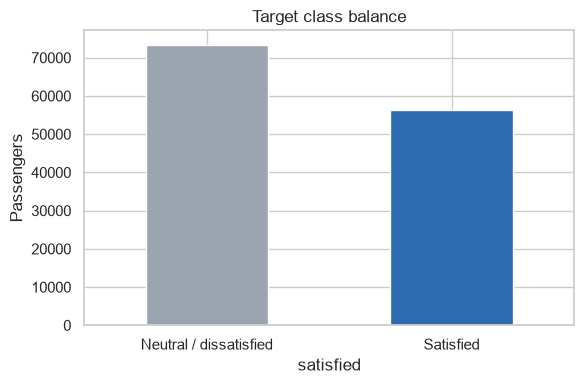

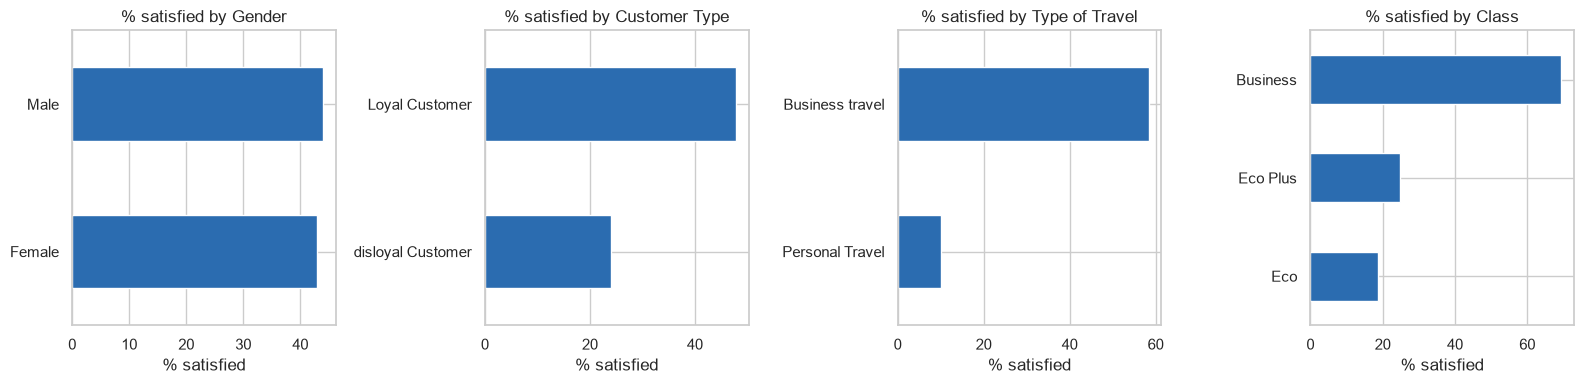

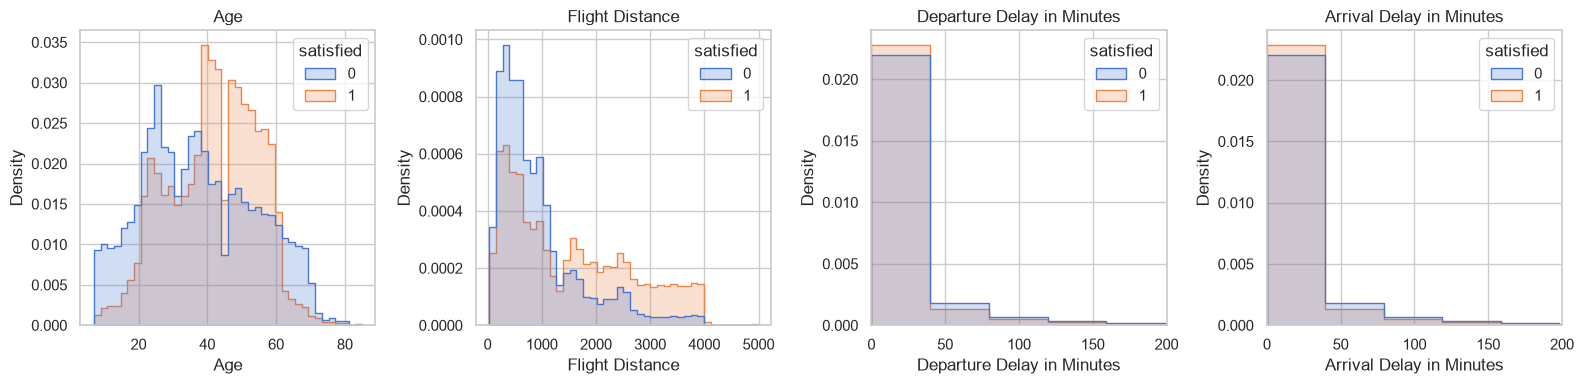

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
air_all[TARGET].map({0: "Neutral / dissatisfied", 1: "Satisfied"}).value_counts().plot.bar(ax=ax, color=["#9aa5b1", "#2b6cb0"])
ax.set_title("Target class balance"); ax.set_ylabel("Passengers"); ax.tick_params(axis="x", rotation=0)
save(fig, "airline_class_balance.png")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, CAT_COLS):
    (air_all.groupby(col)[TARGET].mean() * 100).sort_values().plot.barh(ax=ax, color="#2b6cb0")
    ax.set_title(f"% satisfied by {col}"); ax.set_xlabel("% satisfied"); ax.set_ylabel("")
save(fig, "airline_categorical_vs_target.png")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, NUM_BASE):
    sns.histplot(data=air_all, x=col, hue=TARGET, bins=40, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(col)
    if "Delay" in col:
        ax.set_xlim(0, 200)
save(fig, "airline_numeric_distributions.png")

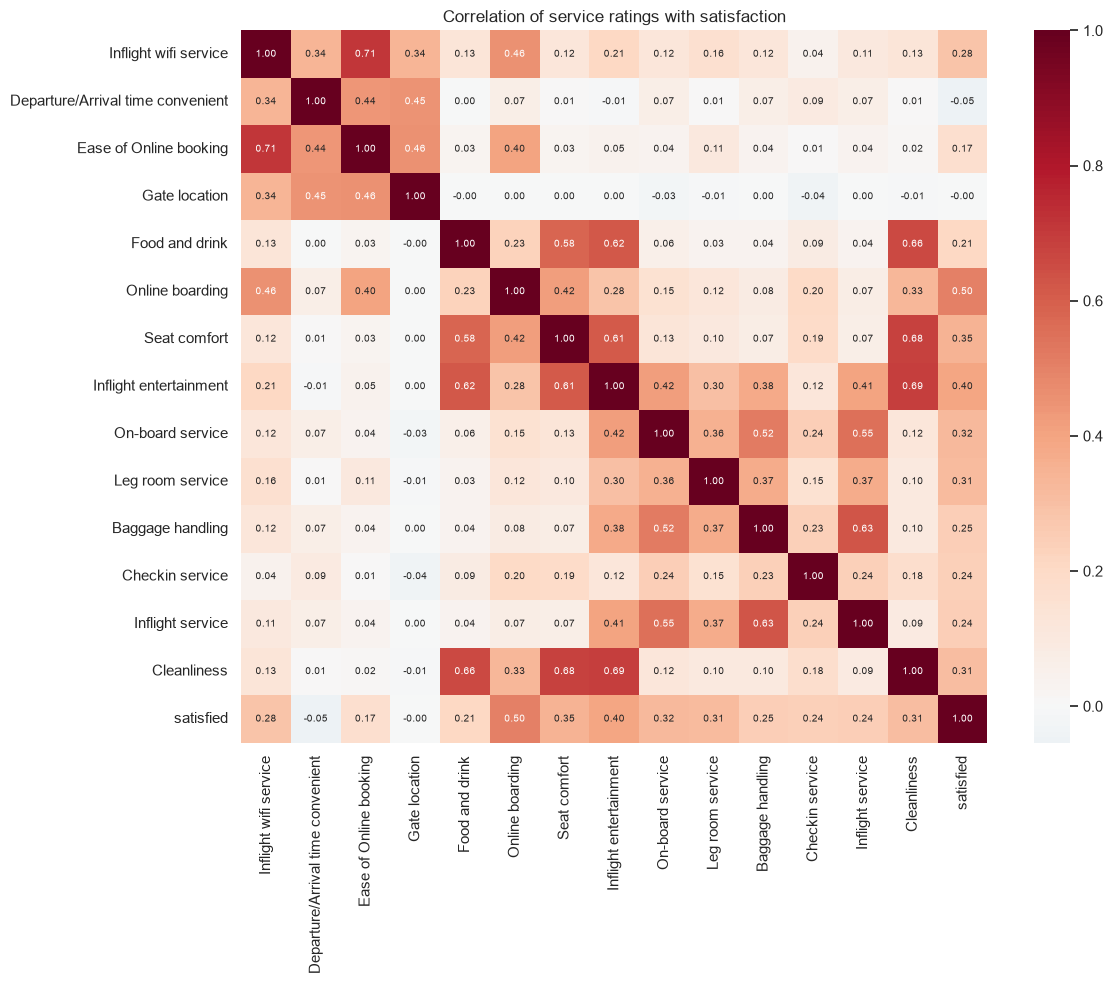

Top correlations with satisfaction: {'Online boarding': 0.502, 'Inflight entertainment': 0.398, 'Seat comfort': 0.349, 'On-board service': 0.322, 'Leg room service': 0.312, 'Cleanliness': 0.307}


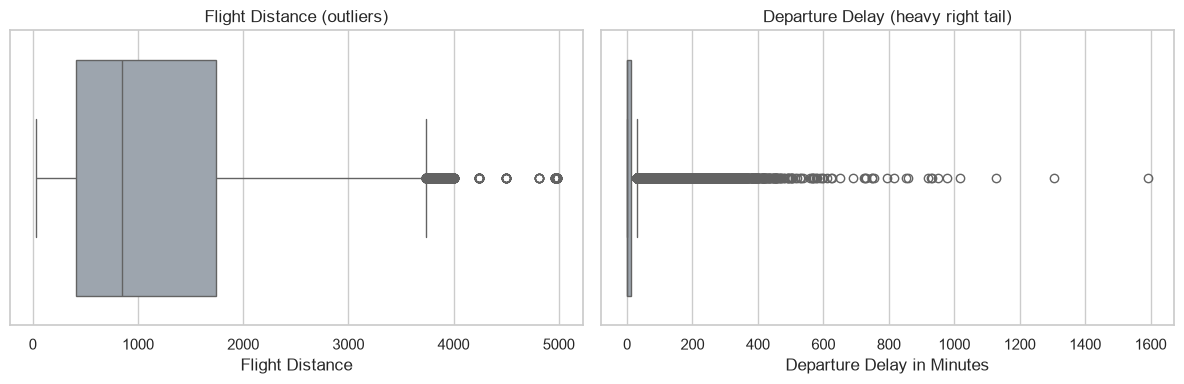

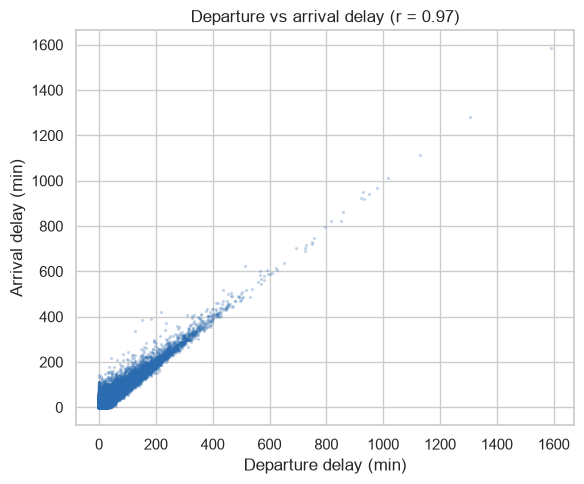

In [5]:
corr = air_all[SERVICE_COLS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation of service ratings with satisfaction")
save(fig, "airline_correlation_heatmap.png")
eda["top_correlations"] = corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).head(6).to_dict()
print("Top correlations with satisfaction:", eda["top_correlations"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=air_all, x="Flight Distance", ax=axes[0], color="#9aa5b1"); axes[0].set_title("Flight Distance (outliers)")
sns.boxplot(data=air_all, x="Departure Delay in Minutes", ax=axes[1], color="#9aa5b1"); axes[1].set_title("Departure Delay (heavy right tail)")
save(fig, "airline_outliers_boxplot.png")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(air_all["Departure Delay in Minutes"], air_all["Arrival Delay in Minutes"], s=2, alpha=0.2, color="#2b6cb0")
ax.set_xlabel("Departure delay (min)"); ax.set_ylabel("Arrival delay (min)")
r = air_all[["Departure Delay in Minutes", "Arrival Delay in Minutes"]].corr().iloc[0, 1]
ax.set_title(f"Departure vs arrival delay (r = {r:.2f})")
save(fig, "airline_delay_scatter.png")

### 3.2 Data cleaning and feature engineering
- Drop duplicate rows.
- Fill the missing *Arrival Delay* values (about 0.3 %) with the departure delay, since the two are highly correlated (r ≈ 0.96).
- Cap extreme delays at the training 99.5th percentile. The test set uses the same caps, so no test information leaks into training.
- New features: mean and minimum service rating (0 = "not applicable" is ignored), number of low (≤ 2) ratings, total delay, delay gained in the air, and log flight distance.

In [6]:
def air_clean(df, report=None, fit_stats=None):
    df = df.copy()
    before = len(df)
    df = df.drop_duplicates()
    miss = df["Arrival Delay in Minutes"].isna()
    df.loc[miss, "Arrival Delay in Minutes"] = df.loc[miss, "Departure Delay in Minutes"]
    if fit_stats is None:
        fit_stats = {c: float(df[c].quantile(0.995)) for c in ["Departure Delay in Minutes", "Arrival Delay in Minutes"]}
    for c, cap in fit_stats.items():
        df[c] = df[c].clip(upper=cap)
    if report is not None:
        report["cleaning"] = {"duplicates_removed": before - len(df), "arrival_delay_imputed": int(miss.sum()),
                              "delay_caps_p99_5": fit_stats}
    return df, fit_stats


def air_engineer(df):
    df = df.copy()
    ratings = df[SERVICE_COLS].replace(0, np.nan)  # 0 = "not applicable" in this survey
    df["service_mean"] = ratings.mean(axis=1)
    df["service_min"] = ratings.min(axis=1)
    df["low_scores"] = (ratings <= 2).sum(axis=1)
    df["total_delay"] = df["Departure Delay in Minutes"] + df["Arrival Delay in Minutes"]
    df["delay_gained"] = df["Arrival Delay in Minutes"] - df["Departure Delay in Minutes"]
    df["log_distance"] = np.log1p(df["Flight Distance"])
    return df


air_train, air_stats = air_clean(air_train_raw, air_report)
air_test, _ = air_clean(air_test_raw, fit_stats=air_stats)
air_train, air_test = air_engineer(air_train), air_engineer(air_test)
print(air_report["cleaning"])
air_train[ENGINEERED].describe().T

{'duplicates_removed': 0, 'arrival_delay_imputed': 310, 'delay_caps_p99_5': {'Departure Delay in Minutes': 233.0, 'Arrival Delay in Minutes': 239.0}}


,count,mean,std,min,25%,50%,75%,max
service_mean,103904.0,3.276516,0.652978,1.142857,2.785714,3.285714,3.727273,5.000000
service_min,103904.0,1.568640,0.762087,1.000000,1.000000,1.000000,2.000000,5.000000
low_scores,103904.0,4.080671,2.995282,0.000000,1.000000,4.000000,6.000000,14.000000
total_delay,103904.0,29.076571,66.575115,0.000000,0.000000,2.000000,24.000000,472.000000
delay_gained,103904.0,0.436595,9.853723,-51.000000,-2.000000,0.000000,0.000000,177.000000
log_distance,103904.0,6.705596,0.915590,3.465736,6.028279,6.738152,7.463937,8.513988


### 3.3 Data splitting
The Kaggle training file is split 80/20 into **train** and **validation** (stratified). The Kaggle test file is kept as the untouched **test** set.

In [7]:
X, y = air_train[NUM_COLS + CAT_COLS], air_train[TARGET]
Xa_tr, Xa_val, ya_tr, ya_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
Xa_te, ya_te = air_test[NUM_COLS + CAT_COLS], air_test[TARGET]
air_report["split"] = {"train": len(Xa_tr), "validation": len(Xa_val), "test": len(Xa_te)}
air_report["split"]

{'train': 83123, 'validation': 20781, 'test': 25976}

## 4. Algorithm selection
Four candidate algorithms, from simple to complex: **Logistic Regression** (linear baseline), **Random Forest** (bagging), **XGBoost** and **LightGBM** (gradient boosting).
Numeric features are imputed (and scaled for the linear model), and categorical features are one-hot encoded inside one `Pipeline`, so preprocessing is learned from the training data only.

In [8]:
def make_preprocessor(scale=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else []))
    return ColumnTransformer([("num", num, NUM_COLS),
                              ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT_COLS)])


def clf_metrics(y, pred, proba):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, proba)}


air_candidates = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(max_iter=2000))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(False)), ("clf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED))]),
    "XGBoost": Pipeline([("prep", make_preprocessor(False)), ("clf", XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=6, eval_metric="logloss", n_jobs=-1, random_state=SEED))]),
    "LightGBM": Pipeline([("prep", make_preprocessor(False)), ("clf", LGBMClassifier(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1, n_jobs=1))]),
}

## 5. Model development and training
Each candidate is trained on the training set and scored on both train and validation, so we can check for over- or underfitting.

In [9]:
air_baseline = {}
for name, pipe in air_candidates.items():
    s = time.time(); pipe.fit(Xa_tr, ya_tr); fit_s = time.time() - s
    tr = clf_metrics(ya_tr, pipe.predict(Xa_tr), pipe.predict_proba(Xa_tr)[:, 1])
    va = clf_metrics(ya_val, pipe.predict(Xa_val), pipe.predict_proba(Xa_val)[:, 1])
    air_baseline[name] = {"train": r4(tr), "validation": r4(va), "fit_seconds": round(fit_s, 1),
                          "train_val_gap_accuracy": round(tr["accuracy"] - va["accuracy"], 4)}
    print(f"{name:20s} val acc={va['accuracy']:.4f} f1={va['f1']:.4f} auc={va['roc_auc']:.4f} gap={tr['accuracy'] - va['accuracy']:.4f}")
air_report["baseline"] = air_baseline

pd.DataFrame({n: {**{f"val_{k}": v for k, v in b["validation"].items()}, "gap_acc": b["train_val_gap_accuracy"],
                  "fit_s": b["fit_seconds"]} for n, b in air_baseline.items()}).T

Logistic Regression  val acc=0.8965 f1=0.8801 auc=0.9568 gap=0.0004


Random Forest        val acc=0.9609 f1=0.9543 auc=0.9937 gap=0.0391


XGBoost              val acc=0.9638 f1=0.9578 auc=0.9954 gap=0.0162


LightGBM             val acc=0.9648 f1=0.9589 auc=0.9956 gap=0.0084


,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,gap_acc,fit_s
Logistic Regression,0.8965,0.8833,0.8770,0.8801,0.9568,0.0004,0.4
Random Forest,0.9609,0.9666,0.9424,0.9543,0.9937,0.0391,2.8
XGBoost,0.9638,0.9680,0.9478,0.9578,0.9954,0.0162,1.7
LightGBM,0.9648,0.9716,0.9465,0.9589,0.9956,0.0084,3.1


## 6. Model evaluation and hyperparameter tuning
- **Grid search** over the Logistic Regression's regularisation strength `C` (small, interpretable search space).
- **Random search** (25 trials) over the LightGBM hyperparameters (larger, continuous search space).

Both use 5-fold stratified cross-validation on the training set, with F1 as the score.

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
air_tuning = {}

gs = GridSearchCV(air_candidates["Logistic Regression"], {"clf__C": [0.01, 0.1, 1, 10], "clf__penalty": ["l2"]},
                  scoring="f1", cv=cv, n_jobs=-1).fit(Xa_tr, ya_tr)
air_tuning["Logistic Regression (Grid Search)"] = {"best_params": gs.best_params_, "cv_f1": round(gs.best_score_, 4)}

lgb_space = {"clf__n_estimators": randint(300, 1200), "clf__learning_rate": loguniform(0.01, 0.2),
             "clf__num_leaves": randint(31, 255), "clf__min_child_samples": randint(10, 100),
             "clf__subsample": uniform(0.6, 0.4), "clf__subsample_freq": [1],
             "clf__colsample_bytree": uniform(0.5, 0.5), "clf__reg_lambda": loguniform(1e-3, 10)}
air_rs = RandomizedSearchCV(air_candidates["LightGBM"], lgb_space, n_iter=25, scoring="f1", cv=cv,
                            random_state=SEED, n_jobs=-1, verbose=1).fit(Xa_tr, ya_tr)
air_tuning["LightGBM (Random Search)"] = {
    "best_params": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in air_rs.best_params_.items()},
    "cv_f1": round(air_rs.best_score_, 4)}
print(json.dumps({k: v for k, v in air_tuning.items()}, indent=2, default=str))

C:\Users\aaa\Desktop\olyad_assignment\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Fitting 5 folds for each of 25 candidates, totalling 125 fits


{
  "Logistic Regression (Grid Search)": {
    "best_params": {
      "clf__C": 10,
      "clf__penalty": "l2"
    },
    "cv_f1": 0.8797
  },
  "LightGBM (Random Search)": {
    "best_params": {
      "clf__colsample_bytree": 0.61639,
      "clf__learning_rate": 0.01312,
      "clf__min_child_samples": 71,
      "clf__n_estimators": 862,
      "clf__num_leaves": 138,
      "clf__reg_lambda": 0.11401,
      "clf__subsample": 0.83697,
      "clf__subsample_freq": 1
    },
    "cv_f1": 0.9582
  }
}


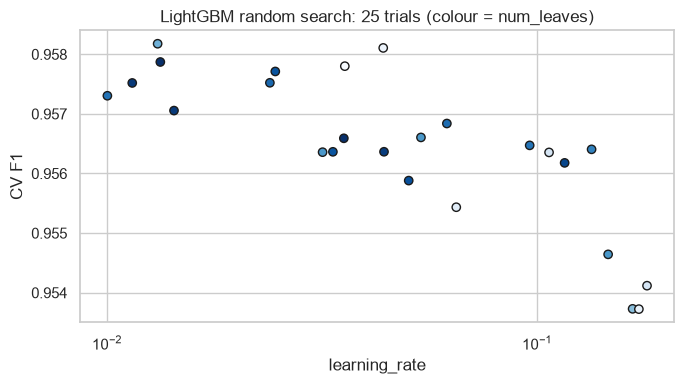

tuned LightGBM  train: {'accuracy': 0.9849, 'precision': 0.9928, 'recall': 0.9721, 'f1': 0.9823, 'roc_auc': 0.9995}
tuned LightGBM  val:   {'accuracy': 0.9661, 'precision': 0.973, 'recall': 0.948, 'f1': 0.9603, 'roc_auc': 0.9958}


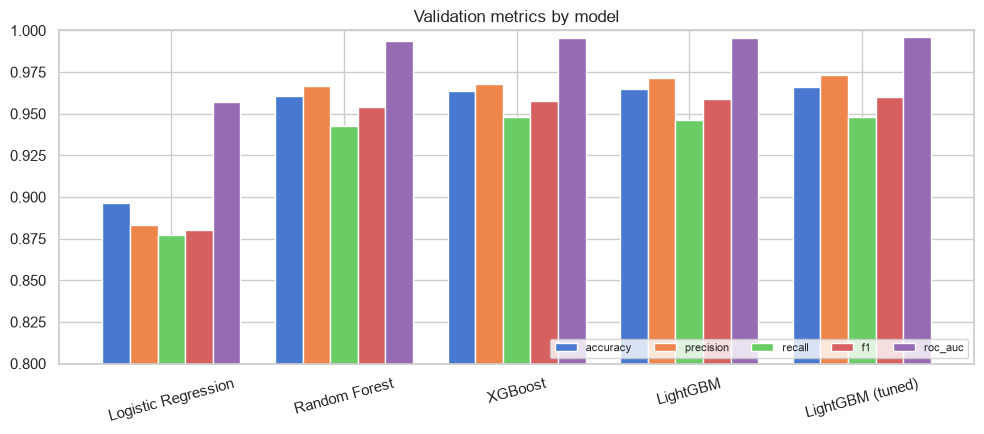

In [11]:
cvres = pd.DataFrame(air_rs.cv_results_).sort_values("rank_test_score")
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(cvres["param_clf__learning_rate"].astype(float), cvres["mean_test_score"],
           c=cvres["param_clf__num_leaves"].astype(float), cmap="Blues", edgecolor="k")
ax.set_xscale("log"); ax.set_xlabel("learning_rate"); ax.set_ylabel("CV F1")
ax.set_title("LightGBM random search: 25 trials (colour = num_leaves)")
save(fig, "airline_random_search.png")

best = air_rs.best_estimator_
va_best = clf_metrics(ya_val, best.predict(Xa_val), best.predict_proba(Xa_val)[:, 1])
tr_best = clf_metrics(ya_tr, best.predict(Xa_tr), best.predict_proba(Xa_tr)[:, 1])
air_tuning["tuned_lightgbm_validation"] = r4(va_best)
air_tuning["tuned_lightgbm_train"] = r4(tr_best)
air_report["tuning"] = air_tuning
print("tuned LightGBM  train:", r4(tr_best))
print("tuned LightGBM  val:  ", r4(va_best))

comp = pd.DataFrame({n: b["validation"] for n, b in air_baseline.items()}).T
comp.loc["LightGBM (tuned)"] = va_best
fig, ax = plt.subplots(figsize=(10, 4.5))
comp[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot.bar(ax=ax, width=0.8)
ax.set_ylim(0.8, 1.0); ax.set_title("Validation metrics by model"); ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right", ncol=5, fontsize=8)
save(fig, "airline_model_comparison.png")

## 7. Model testing
The tuned LightGBM is refit on train + validation with the same hyperparameters and evaluated **once** on the test set.

TEST {'accuracy': 0.9652, 'precision': 0.975, 'recall': 0.945, 'f1': 0.9598, 'roc_auc': 0.9956}
                      precision    recall  f1-score   support

neutral/dissatisfied     0.9580    0.9811    0.9694     14573
           satisfied     0.9750    0.9450    0.9598     11403

            accuracy                         0.9652     25976
           macro avg     0.9665    0.9630    0.9646     25976
        weighted avg     0.9655    0.9652    0.9652     25976



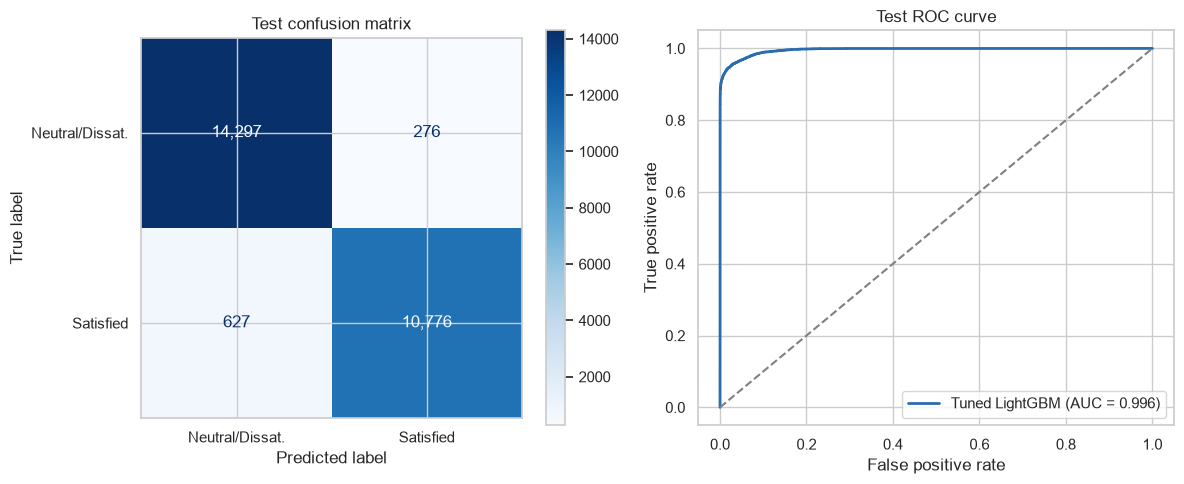

In [12]:
air_final = air_rs.best_estimator_
air_final.fit(pd.concat([Xa_tr, Xa_val]), pd.concat([ya_tr, ya_val]))
proba = air_final.predict_proba(Xa_te)[:, 1]
pred = (proba >= 0.5).astype(int)
air_report["test"] = r4(clf_metrics(ya_te, pred, proba))
air_report["test_classification_report"] = classification_report(
    ya_te, pred, target_names=["neutral/dissatisfied", "satisfied"], output_dict=True)
print("TEST", air_report["test"])
print(classification_report(ya_te, pred, target_names=["neutral/dissatisfied", "satisfied"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(ya_te, pred), display_labels=["Neutral/Dissat.", "Satisfied"]).plot(
    ax=axes[0], cmap="Blues", values_format=",")
axes[0].set_title("Test confusion matrix")
fpr, tpr, _ = roc_curve(ya_te, proba)
axes[1].plot(fpr, tpr, color="#2b6cb0", lw=2, label=f"Tuned LightGBM (AUC = {air_report['test']['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("Test ROC curve"); axes[1].legend(loc="lower right")
save(fig, "airline_test_confusion_roc.png")

### Model interpretation, latency and saving the model

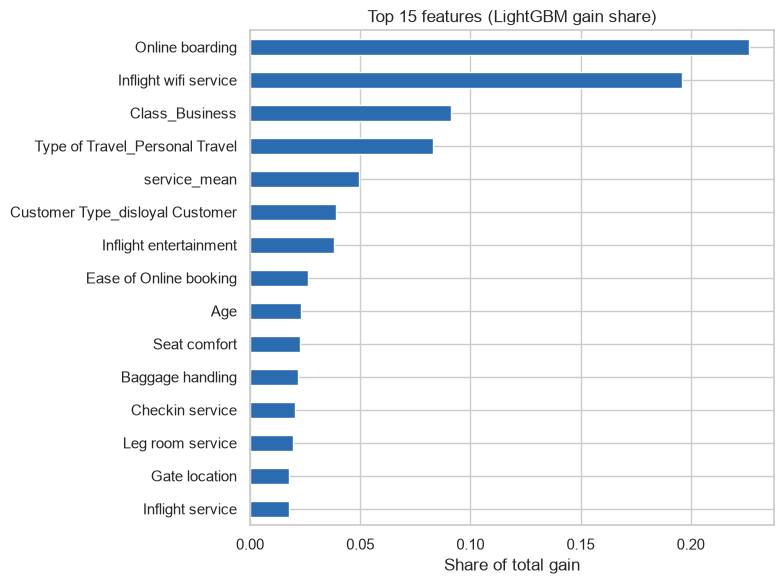

latency: {'p50': 4.44, 'p95': 6.22} | runtime: 274.7 s


In [13]:
names = air_final.named_steps["prep"].get_feature_names_out()
imp = pd.Series(air_final.named_steps["clf"].booster_.feature_importance("gain"), index=[n.split("__", 1)[1] for n in names])
imp = (imp / imp.sum()).sort_values(ascending=False).head(15)
air_report["feature_importance_top15"] = imp.round(4).to_dict()
fig, ax = plt.subplots(figsize=(8, 6))
imp[::-1].plot.barh(ax=ax, color="#2b6cb0"); ax.set_title("Top 15 features (LightGBM gain share)"); ax.set_xlabel("Share of total gain")
save(fig, "airline_feature_importance.png")

# Single-row inference latency, the way the API calls the model
one = Xa_te.iloc[[0]]
lat = []
for _ in range(200):
    s = time.perf_counter(); air_final.predict_proba(one); lat.append((time.perf_counter() - s) * 1000)
air_report["latency_ms_single_row"] = {"p50": round(float(np.percentile(lat, 50)), 2), "p95": round(float(np.percentile(lat, 95)), 2)}

joblib.dump({"model": air_final, "features": NUM_COLS + CAT_COLS, "clean_stats": air_stats,
             "service_cols": SERVICE_COLS, "reference": Xa_tr.sample(5000, random_state=SEED)},
            MODELS / "airline_model.joblib", compress=3)
air_report["runtime_seconds"] = round(time.time() - t0_air, 1)
(REPORTS / "airline_metrics.json").write_text(json.dumps(air_report, indent=2, default=str))
print("latency:", air_report["latency_ms_single_row"], "| runtime:", air_report["runtime_seconds"], "s")

---
# Task B — NYC Taxi Trip Duration (regression)

## 1. Problem definition
Predict a taxi trip's duration in seconds using only information known at pickup: time, pickup and drop-off coordinates, vendor and passenger count.
The model is trained on `log1p(duration)`, so the main metric is **RMSLE** (the Kaggle competition metric). RMSE, MAE and R² are also reported.

- **Success criteria:** test RMSLE ≤ 0.40, R² on log duration ≥ 0.70

## 2. Data collection

In [14]:
NYC_BOX = {"lat": (40.49, 40.92), "lon": (-74.27, -73.68)}
JFK, LGA = (40.6413, -73.7781), (40.7769, -73.8740)
TAXI_FEATURES = ["vendor_id", "passenger_count", "store_and_fwd", "pickup_longitude", "pickup_latitude",
                 "dropoff_longitude", "dropoff_latitude", "hour", "minute_of_day", "weekday", "month",
                 "day_of_year", "is_weekend", "is_rush_hour", "haversine_km", "manhattan_km", "bearing",
                 "delta_lat", "delta_lon", "center_lat", "center_lon", "pickup_jfk", "dropoff_jfk",
                 "pickup_lga", "dropoff_lga", "pickup_cluster", "dropoff_cluster"]

t0_taxi = time.time()
taxi_report = {"project": "NYC Taxi Trip Duration (regression)"}
raw = pd.read_csv(ROOT / "data" / "taxi" / "NYC.csv")
print(raw.shape)
raw.head()

(1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


## 3. Data exploration and preparation
### 3.1 Exploratory data analysis

{
  "rows": 1458644,
  "cols": 11,
  "missing": 0,
  "duplicate_ids": 0,
  "duration_seconds_describe": {
    "count": 1458644.0,
    "mean": 959.5,
    "std": 5237.4,
    "min": 1.0,
    "25%": 397.0,
    "50%": 662.0,
    "75%": 1075.0,
    "max": 3526282.0
  },
  "trips_over_24h": 4,
  "trips_under_60s": 8595,
  "passenger_count_counts": {
    "0": 60,
    "1": 1033540,
    "2": 210318,
    "3": 59896,
    "4": 28404,
    "5": 78088,
    "6": 48333,
    "7": 3,
    "8": 1,
    "9": 1
  }
}


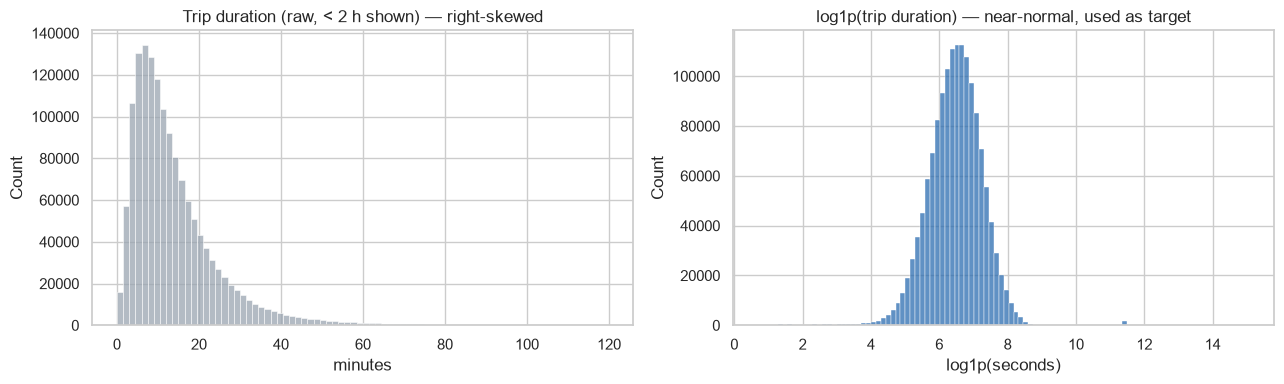

In [15]:
teda = taxi_report.setdefault("eda", {})
teda["rows"], teda["cols"] = int(raw.shape[0]), int(raw.shape[1])
teda["missing"] = int(raw.isna().sum().sum())
teda["duplicate_ids"] = int(raw["id"].duplicated().sum())
teda["duration_seconds_describe"] = raw["trip_duration"].describe().round(1).to_dict()
teda["trips_over_24h"] = int((raw["trip_duration"] > 86400).sum())
teda["trips_under_60s"] = int((raw["trip_duration"] < 60).sum())
teda["passenger_count_counts"] = raw["passenger_count"].value_counts().sort_index().to_dict()
print(json.dumps(teda, indent=2, default=str))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(raw.loc[raw.trip_duration < 7200, "trip_duration"] / 60, bins=80, ax=axes[0], color="#9aa5b1")
axes[0].set_title("Trip duration (raw, < 2 h shown) — right-skewed"); axes[0].set_xlabel("minutes")
sns.histplot(np.log1p(raw["trip_duration"]), bins=100, ax=axes[1], color="#2b6cb0")
axes[1].set_title("log1p(trip duration) — near-normal, used as target"); axes[1].set_xlabel("log1p(seconds)")
save(fig, "taxi_target_distribution.png")

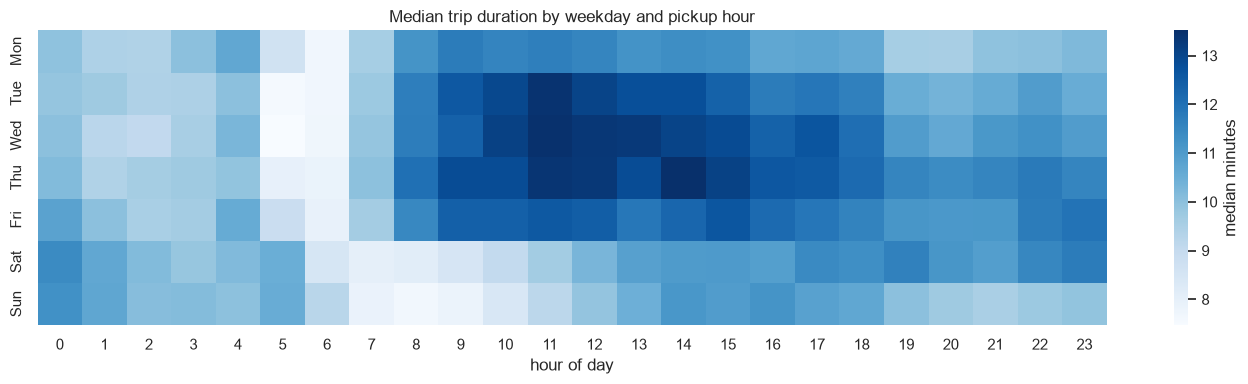

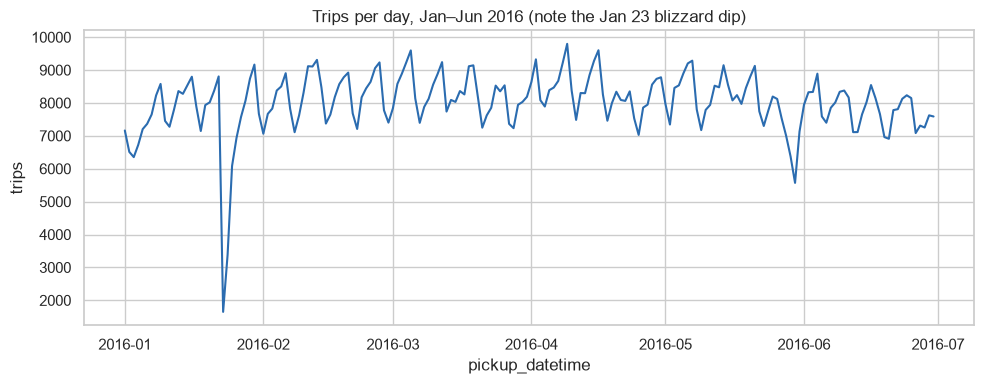

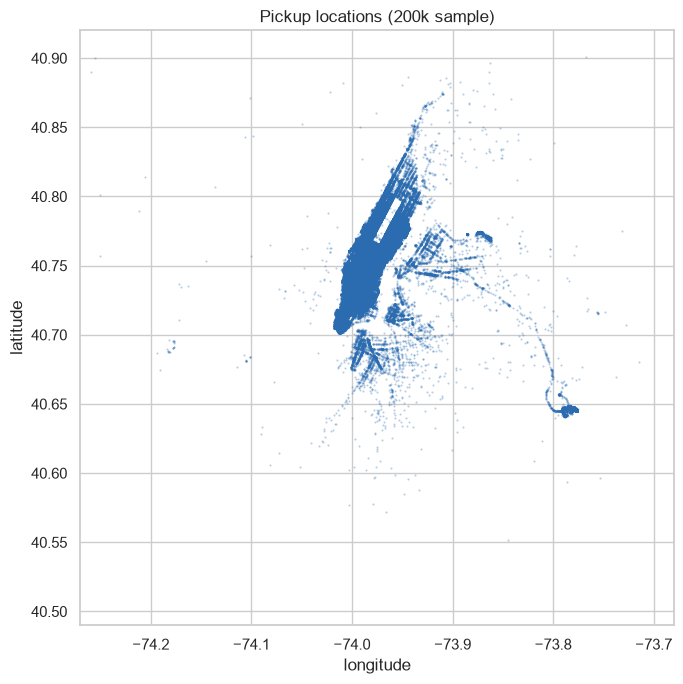

In [16]:
t = pd.to_datetime(raw["pickup_datetime"])
piv = raw.assign(h=t.dt.hour, wd=t.dt.day_name().str[:3]).pivot_table(index="wd", columns="h", values="trip_duration", aggfunc="median") / 60
piv = piv.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(piv, cmap="Blues", ax=ax, cbar_kws={"label": "median minutes"})
ax.set_title("Median trip duration by weekday and pickup hour"); ax.set_xlabel("hour of day"); ax.set_ylabel("")
save(fig, "taxi_hour_weekday_heatmap.png")

fig, ax = plt.subplots(figsize=(10, 4))
t.dt.date.value_counts().sort_index().plot(ax=ax, color="#2b6cb0")
ax.set_title("Trips per day, Jan–Jun 2016 (note the Jan 23 blizzard dip)"); ax.set_ylabel("trips")
save(fig, "taxi_trips_per_day.png")

s = raw.sample(200_000, random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(s.pickup_longitude, s.pickup_latitude, s=0.3, alpha=0.3, color="#2b6cb0")
ax.set_xlim(*NYC_BOX["lon"]); ax.set_ylim(*NYC_BOX["lat"]); ax.set_title("Pickup locations (200k sample)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
save(fig, "taxi_pickup_map.png")

### 3.2 Data cleaning
The following rows are removed: duplicate IDs, trips that start or end outside the NYC bounding box, durations shorter than 60 s or longer than 4 h, passenger counts outside 1–6, near-zero distances, and average speeds above 120 km/h (GPS or clock errors).

In [17]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


def bearing(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    y = np.sin(lon2 - lon1) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon2 - lon1)
    return np.degrees(np.arctan2(y, x))


df = raw.drop_duplicates(subset="id").copy()
n0 = len(df)
steps = {}
inbox = (df.pickup_latitude.between(*NYC_BOX["lat"]) & df.dropoff_latitude.between(*NYC_BOX["lat"]) &
         df.pickup_longitude.between(*NYC_BOX["lon"]) & df.dropoff_longitude.between(*NYC_BOX["lon"]))
steps["outside_nyc_bbox"] = int((~inbox).sum()); df = df[inbox]
ok = df.trip_duration.between(60, 4 * 3600)
steps["duration_outside_60s_4h"] = int((~ok).sum()); df = df[ok]
ok = df.passenger_count.between(1, 6)
steps["passenger_count_not_1_to_6"] = int((~ok).sum()); df = df[ok]
d = haversine(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
ok = d > 0.05
steps["zero_distance_trips"] = int((~ok).sum()); df = df[ok]
speed = d[ok] / (df.trip_duration / 3600)
ok = speed < 120
steps["speed_over_120kmh"] = int((~ok).sum()); df = df[ok]
steps["rows_kept"] = len(df); steps["rows_removed_pct"] = round(100 * (1 - len(df) / n0), 2)
taxi_report["cleaning"] = steps
steps

{'outside_nyc_bbox': 1211,
 'duration_outside_60s_4h': 10504,
 'passenger_count_not_1_to_6': 19,
 'zero_distance_trips': 6136,
 'speed_over_120kmh': 21,
 'rows_kept': 1440753,
 'rows_removed_pct': 1.23}

### 3.3 Data splitting and feature engineering
Split 70 / 15 / 15 into train, validation and test.
Features: time of day, weekday and month, weekend and rush-hour flags, haversine and Manhattan distance, bearing, coordinate deltas and midpoint, airport (JFK / LGA) flags, and **K-Means location clusters** (60 clusters fit on training coordinates only).

In [18]:
def add_features(df, kmeans=None):
    df = df.copy()
    t = pd.to_datetime(df["pickup_datetime"])
    df["hour"] = t.dt.hour
    df["minute_of_day"] = t.dt.hour * 60 + t.dt.minute
    df["weekday"] = t.dt.weekday
    df["month"] = t.dt.month
    df["day_of_year"] = t.dt.dayofyear
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    df["is_rush_hour"] = (df["weekday"].lt(5) & (df["hour"].between(7, 9) | df["hour"].between(16, 19))).astype(int)
    plat, plon, dlat, dlon = df["pickup_latitude"], df["pickup_longitude"], df["dropoff_latitude"], df["dropoff_longitude"]
    df["haversine_km"] = haversine(plat, plon, dlat, dlon)
    df["manhattan_km"] = haversine(plat, plon, plat, dlon) + haversine(plat, dlon, dlat, dlon)
    df["bearing"] = bearing(plat, plon, dlat, dlon)
    df["delta_lat"], df["delta_lon"] = dlat - plat, dlon - plon
    df["center_lat"], df["center_lon"] = (plat + dlat) / 2, (plon + dlon) / 2
    df["pickup_jfk"] = (haversine(plat, plon, *JFK) < 2).astype(int)
    df["dropoff_jfk"] = (haversine(dlat, dlon, *JFK) < 2).astype(int)
    df["pickup_lga"] = (haversine(plat, plon, *LGA) < 1.5).astype(int)
    df["dropoff_lga"] = (haversine(dlat, dlon, *LGA) < 1.5).astype(int)
    df["store_and_fwd"] = (df["store_and_fwd_flag"] == "Y").astype(int)
    if kmeans is not None:
        df["pickup_cluster"] = kmeans.predict(df[["pickup_latitude", "pickup_longitude"]].to_numpy())
        df["dropoff_cluster"] = kmeans.predict(df[["dropoff_latitude", "dropoff_longitude"]].to_numpy())
    return df


train, temp = train_test_split(df, test_size=0.30, random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, random_state=SEED)
taxi_report["split"] = {"train": len(train), "validation": len(val), "test": len(test)}
print(taxi_report["split"])

coords = np.vstack([train[["pickup_latitude", "pickup_longitude"]].to_numpy(),
                    train[["dropoff_latitude", "dropoff_longitude"]].to_numpy()])
kmeans = MiniBatchKMeans(n_clusters=60, batch_size=10_000, random_state=SEED, n_init=3).fit(
    coords[np.random.default_rng(SEED).choice(len(coords), 500_000, replace=False)])
train, val, test = (add_features(x, kmeans) for x in (train, val, test))
Xtr, ytr = train[TAXI_FEATURES], np.log1p(train.trip_duration)
Xva, yva = val[TAXI_FEATURES], np.log1p(val.trip_duration)
Xte, yte = test[TAXI_FEATURES], np.log1p(test.trip_duration)
Xtr.head()

{'train': 1008527, 'validation': 216113, 'test': 216113}


C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\1187159137.py:6: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekday"] = t.dt.weekday
C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\1187159137.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = t.dt.dayofyear


C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\1187159137.py:6: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekday"] = t.dt.weekday
C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\1187159137.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = t.dt.dayofyear


C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\1187159137.py:6: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekday"] = t.dt.weekday
C:\Users\aaa\AppData\Local\Temp\ipykernel_49712\1187159137.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = t.dt.dayofyear


,vendor_id,passenger_count,store_and_fwd,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,hour,minute_of_day,weekday,month,day_of_year,is_weekend,is_rush_hour,haversine_km,manhattan_km,bearing,delta_lat,delta_lon,center_lat,center_lon,pickup_jfk,dropoff_jfk,pickup_lga,dropoff_lga,pickup_cluster,dropoff_cluster
121356,1,1,0,-73.962357,40.763142,-73.982826,40.758739,18,1107,3,2,56,0,1,1.792171,2.213468,-105.843994,-0.004402,-0.020470,40.760941,-73.972591,0,0,0,0,33,58
639101,1,1,0,-74.012260,40.701485,-73.980713,40.760120,8,523,3,2,56,0,1,7.041066,9.179414,22.170796,0.058636,0.031548,40.730803,-73.996487,0,0,0,0,0,58
858482,1,1,0,-73.983337,40.676876,-73.992889,40.694347,23,1391,4,2,57,0,0,2.103059,2.748241,-22.514826,0.017471,-0.009552,40.685612,-73.988113,0,0,0,0,28,54
812164,1,1,0,-74.006378,40.733177,-74.000633,40.742371,21,1276,2,6,181,0,0,1.131062,1.506322,25.335052,0.009193,0.005745,40.737774,-74.003506,0,0,0,0,11,23
228626,1,2,0,-73.870911,40.773766,-73.902740,40.770542,23,1415,6,1,17,1,0,2.704227,3.038731,-97.606205,-0.003223,-0.031830,40.772154,-73.886826,0,0,1,0,56,13


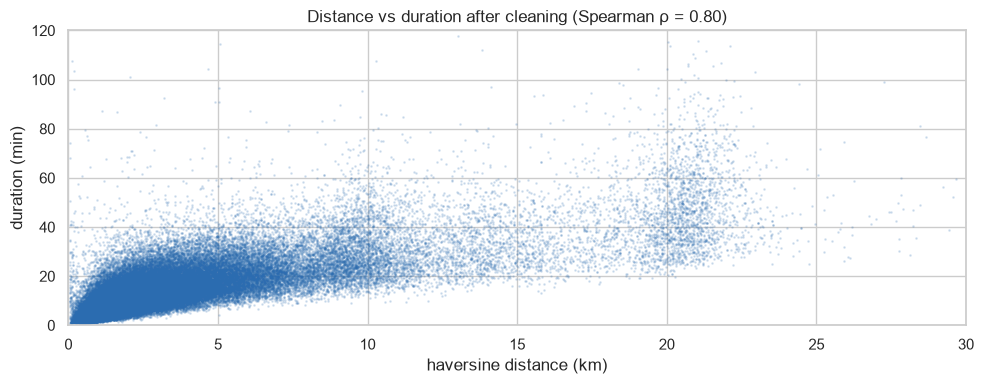

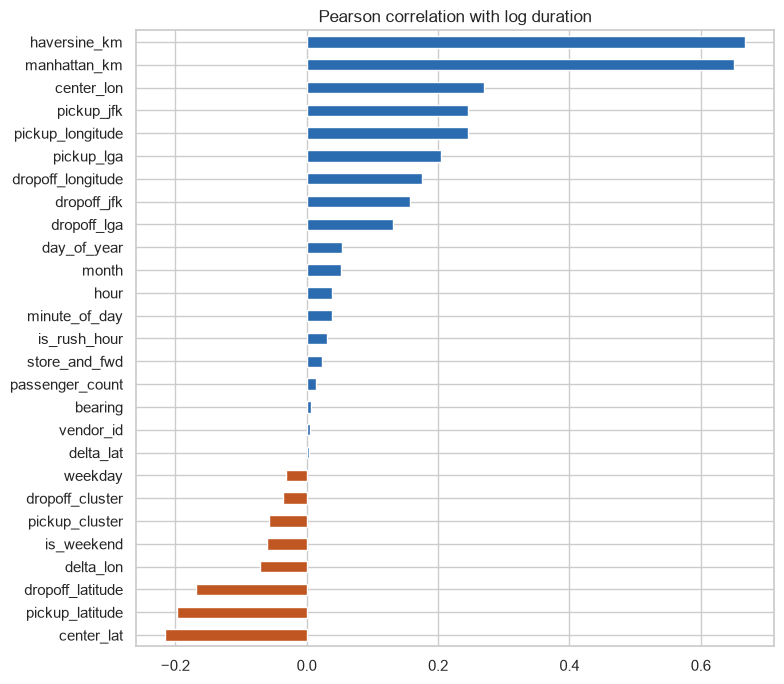

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
s = train.sample(100_000, random_state=SEED)
ax.scatter(s.haversine_km, s.trip_duration / 60, s=1, alpha=0.15, color="#2b6cb0")
ax.set_xlim(0, 30); ax.set_ylim(0, 120); ax.set_xlabel("haversine distance (km)"); ax.set_ylabel("duration (min)")
rho = s[["haversine_km", "trip_duration"]].corr("spearman").iloc[0, 1]
ax.set_title(f"Distance vs duration after cleaning (Spearman ρ = {rho:.2f})")
save(fig, "taxi_distance_vs_duration.png")

corr = train[TAXI_FEATURES].assign(log_duration=ytr).corr()["log_duration"].drop("log_duration").sort_values()
taxi_report["feature_target_correlation"] = corr.round(3).to_dict()
fig, ax = plt.subplots(figsize=(8, 7))
corr.plot.barh(ax=ax, color=["#c05621" if v < 0 else "#2b6cb0" for v in corr]); ax.set_title("Pearson correlation with log duration")
save(fig, "taxi_feature_correlation.png")

## 4. Algorithm selection
Candidates: **mean baseline**, **Ridge Regression**, **Random Forest** (trained on a 200k-row sample to keep the run time reasonable), **XGBoost** and **LightGBM**.

## 5. Model development and training

In [20]:
def reg_metrics(y_log, pred_log):
    y, p = np.expm1(y_log), np.expm1(pred_log)
    return {"rmsle": float(np.sqrt(mean_squared_error(y_log, pred_log))),
            "r2_log": float(r2_score(y_log, pred_log)),
            "rmse_seconds": float(np.sqrt(mean_squared_error(y, p))),
            "mae_seconds": float(mean_absolute_error(y, p)),
            "median_ae_seconds": float(np.median(np.abs(y - p))),
            "r2_seconds": float(r2_score(y, p))}


sub = Xtr.sample(200_000, random_state=SEED); ysub = ytr.loc[sub.index]
taxi_candidates = {
    "Mean baseline": None,
    "Ridge Regression": Pipeline([("scale", StandardScaler()), ("reg", Ridge(alpha=1.0))]),
    "Random Forest (200k sample)": RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED),
    "XGBoost": XGBRegressor(n_estimators=600, learning_rate=0.1, max_depth=8, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED, tree_method="hist"),
    "LightGBM": LGBMRegressor(n_estimators=600, learning_rate=0.1, num_leaves=127, random_state=SEED, verbose=-1),
}
taxi_baseline = {}
for name, model in taxi_candidates.items():
    s0 = time.time()
    if model is None:
        ptr, pva = np.full(len(ytr), ytr.mean()), np.full(len(yva), ytr.mean())
    else:
        X_fit, y_fit = (sub, ysub) if "sample" in name else (Xtr, ytr)
        model.fit(X_fit, y_fit)
        ptr, pva = model.predict(Xtr.iloc[:200_000]), model.predict(Xva)
    tr = reg_metrics(ytr.iloc[:len(ptr)], ptr); va = reg_metrics(yva, pva)
    taxi_baseline[name] = {"train": r4(tr), "validation": r4(va), "fit_seconds": round(time.time() - s0, 1),
                           "train_val_gap_rmsle": round(va["rmsle"] - tr["rmsle"], 4)}
    print(f"{name:28s} val RMSLE={va['rmsle']:.4f} R2log={va['r2_log']:.4f} gap={va['rmsle'] - tr['rmsle']:.4f}")
taxi_report["baseline"] = taxi_baseline

Mean baseline                val RMSLE=0.7266 R2log=-0.0000 gap=0.0005


Ridge Regression             val RMSLE=0.5093 R2log=0.5086 gap=-0.0002


Random Forest (200k sample)  val RMSLE=0.3224 R2log=0.8031 gap=0.0193


XGBoost                      val RMSLE=0.2935 R2log=0.8369 gap=0.0303


LightGBM                     val RMSLE=0.2927 R2log=0.8377 gap=0.0244


## 6. Model evaluation and hyperparameter tuning
- **Grid search** over Ridge `alpha`, and **random search** (15 trials) over the LightGBM hyperparameters, both with 3-fold CV on a 300k-row sample.
- The best LightGBM settings are then refit on the full training set with up to 4,000 trees and **early stopping** on the validation set.

{
  "Ridge (Grid Search)": {
    "best_params": {
      "reg__alpha": 0.1
    },
    "cv_rmsle": 0.5095
  },
  "LightGBM (Random Search)": {
    "best_params": {
      "colsample_bytree": 0.578,
      "learning_rate": 0.03349,
      "min_child_samples": 107,
      "n_estimators": 800,
      "num_leaves": 435,
      "reg_lambda": 0.25378,
      "subsample": 0.88323,
      "subsample_freq": 1
    },
    "cv_rmsle": 0.2979
  }
}


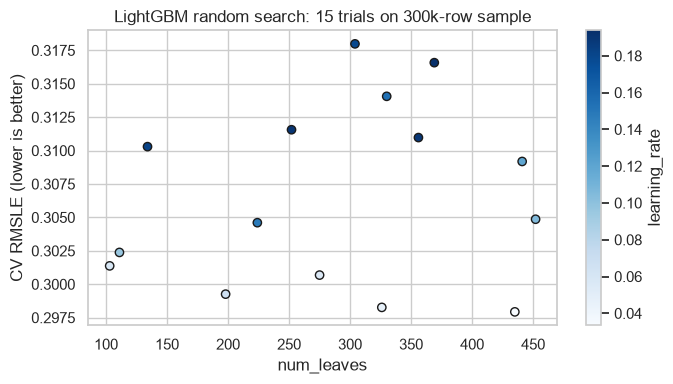

In [21]:
tune = Xtr.sample(300_000, random_state=1); ytune = ytr.loc[tune.index]
cv = KFold(3, shuffle=True, random_state=SEED)
taxi_tuning = {}
gs = GridSearchCV(taxi_candidates["Ridge Regression"], {"reg__alpha": [0.01, 0.1, 1, 10, 100]},
                  scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1).fit(tune, ytune)
taxi_tuning["Ridge (Grid Search)"] = {"best_params": gs.best_params_, "cv_rmsle": round(-gs.best_score_, 4)}
space = {"n_estimators": [800], "learning_rate": loguniform(0.03, 0.2), "num_leaves": randint(63, 511),
         "min_child_samples": randint(20, 200), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
         "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-3, 10)}
taxi_rs = RandomizedSearchCV(LGBMRegressor(random_state=SEED, verbose=-1, n_jobs=2), space, n_iter=15,
                             scoring="neg_root_mean_squared_error", cv=cv, random_state=SEED, n_jobs=4).fit(tune, ytune)
taxi_tuning["LightGBM (Random Search)"] = {
    "best_params": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in taxi_rs.best_params_.items()},
    "cv_rmsle": round(-taxi_rs.best_score_, 4)}
print(json.dumps(taxi_tuning, indent=2, default=str))

cvres = pd.DataFrame(taxi_rs.cv_results_)
fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(cvres["param_num_leaves"].astype(float), -cvres["mean_test_score"],
                c=cvres["param_learning_rate"].astype(float), cmap="Blues", edgecolor="k")
plt.colorbar(sc, label="learning_rate"); ax.set_xlabel("num_leaves"); ax.set_ylabel("CV RMSLE (lower is better)")
ax.set_title("LightGBM random search: 15 trials on 300k-row sample")
save(fig, "taxi_random_search.png")

C:\Users\aaa\Desktop\olyad_assignment\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


tuned LightGBM val {'rmsle': 0.2828, 'r2_log': 0.8485, 'rmse_seconds': 262.0678, 'mae_seconds': 151.848, 'median_ae_seconds': 94.3457, 'r2_seconds': 0.8404} | best iteration 4000


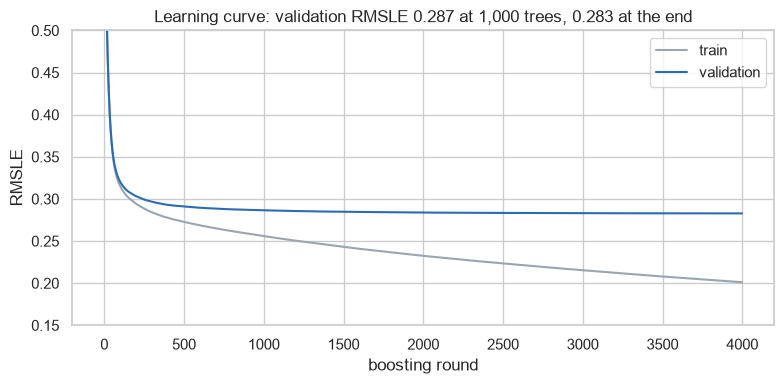

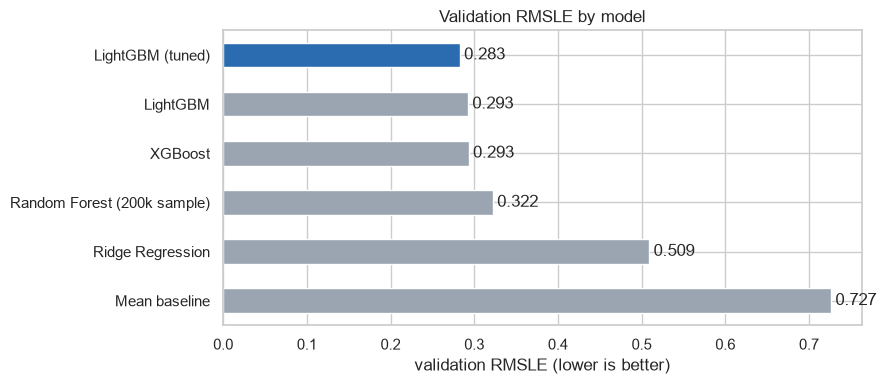

In [22]:
params = {**taxi_rs.best_params_, "n_estimators": 4000, "n_jobs": -1}
taxi_final = LGBMRegressor(**params, random_state=SEED, verbose=-1)
taxi_final.fit(Xtr, ytr, eval_set=[(Xtr.iloc[:200_000], ytr.iloc[:200_000]), (Xva, yva)], eval_names=["train", "validation"],
               eval_metric="rmse", callbacks=[early_stopping(100, verbose=False)])
taxi_tuning["final_best_iteration"] = int(taxi_final.best_iteration_)
va_best = reg_metrics(yva, taxi_final.predict(Xva))
tr_best = reg_metrics(ytr.iloc[:200_000], taxi_final.predict(Xtr.iloc[:200_000]))
taxi_tuning["tuned_lightgbm_validation"] = r4(va_best); taxi_tuning["tuned_lightgbm_train"] = r4(tr_best)
taxi_report["tuning"] = taxi_tuning
print("tuned LightGBM val", r4(va_best), "| best iteration", taxi_final.best_iteration_)

ev = taxi_final.evals_result_
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ev["train"]["rmse"], label="train", color="#9aa5b1"); ax.plot(ev["validation"]["rmse"], label="validation", color="#2b6cb0")
ax.set_ylim(0.15, 0.5); ax.set_xlabel("boosting round"); ax.set_ylabel("RMSLE"); ax.legend()
at1k = ev["validation"]["rmse"][min(999, len(ev["validation"]["rmse"]) - 1)]
ax.set_title(f"Learning curve: validation RMSLE {at1k:.3f} at 1,000 trees, {ev['validation']['rmse'][-1]:.3f} at the end")
save(fig, "taxi_learning_curve.png")

comp = pd.Series({n: b["validation"]["rmsle"] for n, b in taxi_baseline.items()})
comp["LightGBM (tuned)"] = va_best["rmsle"]
comp = comp.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
comp.plot.barh(ax=ax, color=["#2b6cb0" if "tuned" in n else "#9aa5b1" for n in comp.index])
for i, v in enumerate(comp):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlabel("validation RMSLE (lower is better)"); ax.set_title("Validation RMSLE by model")
save(fig, "taxi_model_comparison.png")

## 7. Model testing
The final model is evaluated **once** on the held-out 15 % test set.

TEST {'rmsle': 0.2804, 'r2_log': 0.8508, 'rmse_seconds': 260.6451, 'mae_seconds': 151.1311, 'median_ae_seconds': 94.1465, 'r2_seconds': 0.8421}


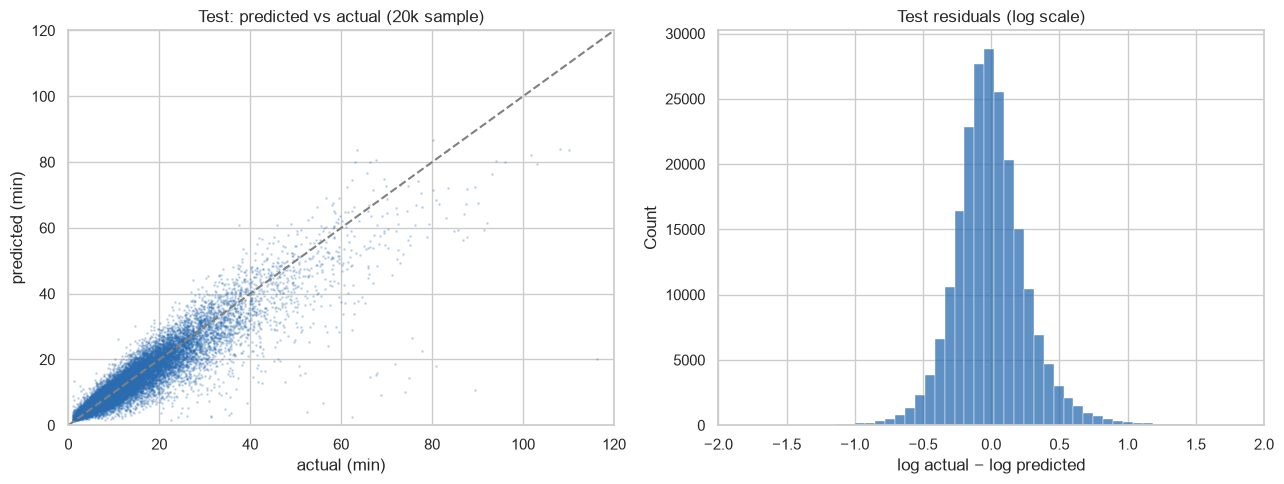

In [23]:
pte = taxi_final.predict(Xte)
taxi_report["test"] = r4(reg_metrics(yte, pte))
print("TEST", taxi_report["test"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
idx = np.random.default_rng(SEED).choice(len(yte), 20_000, replace=False)
axes[0].scatter(np.expm1(yte.iloc[idx]) / 60, np.expm1(pte[idx]) / 60, s=1, alpha=0.2, color="#2b6cb0")
axes[0].plot([0, 120], [0, 120], "--", color="grey"); axes[0].set_xlim(0, 120); axes[0].set_ylim(0, 120)
axes[0].set_xlabel("actual (min)"); axes[0].set_ylabel("predicted (min)"); axes[0].set_title("Test: predicted vs actual (20k sample)")
sns.histplot(yte - pte, bins=100, ax=axes[1], color="#2b6cb0"); axes[1].set_xlim(-2, 2)
axes[1].set_title("Test residuals (log scale)"); axes[1].set_xlabel("log actual − log predicted")
save(fig, "taxi_test_pred_vs_actual.png")

### Model interpretation, latency and saving the model

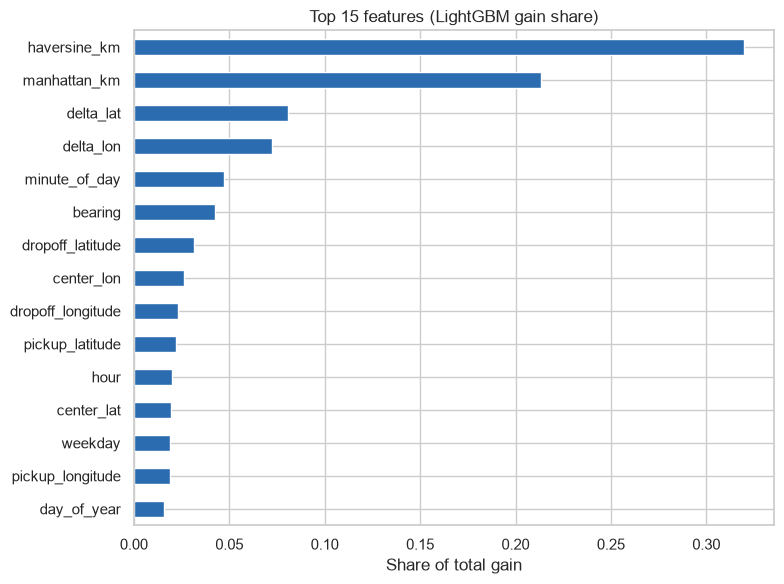

latency: {'p50': 3.51, 'p95': 6.37} | runtime: 884.2 s


In [24]:
imp = pd.Series(taxi_final.booster_.feature_importance("gain"), index=TAXI_FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False).head(15)
taxi_report["feature_importance_top15"] = imp.round(4).to_dict()
fig, ax = plt.subplots(figsize=(8, 6))
imp[::-1].plot.barh(ax=ax, color="#2b6cb0"); ax.set_title("Top 15 features (LightGBM gain share)"); ax.set_xlabel("Share of total gain")
save(fig, "taxi_feature_importance.png")

one = Xte.iloc[[0]]
lat = []
for _ in range(200):
    s0 = time.perf_counter(); taxi_final.predict(one); lat.append((time.perf_counter() - s0) * 1000)
taxi_report["latency_ms_single_row"] = {"p50": round(float(np.percentile(lat, 50)), 2), "p95": round(float(np.percentile(lat, 95)), 2)}

joblib.dump({"model": taxi_final, "kmeans": kmeans, "features": TAXI_FEATURES,
             "reference": Xtr.sample(5000, random_state=SEED)}, MODELS / "taxi_model.joblib", compress=3)
taxi_report["runtime_seconds"] = round(time.time() - t0_taxi, 1)
(REPORTS / "taxi_metrics.json").write_text(json.dumps(taxi_report, indent=2, default=str))
print("latency:", taxi_report["latency_ms_single_row"], "| runtime:", taxi_report["runtime_seconds"], "s")

---
# 8. Deployment
Both saved models are served in two ways:
- **FastAPI REST service** (`api/main.py`): `POST /predict/airline`, `POST /predict/taxi`, `GET /monitoring`, `GET /health`. Start it with `uvicorn api.main:app --reload`.
- **Streamlit web app** (`app/streamlit_app.py`): start it with `streamlit run app/streamlit_app.py`.

The cell below calls the API in-process (no server needed) with one example from each task.

In [25]:
from fastapi.testclient import TestClient
from api.main import app, LOG

client = TestClient(app)
print(client.get("/health").json())

passenger = air_test_raw.drop(columns=TARGET).iloc[0].to_dict()
passenger = {k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v)) for k, v in passenger.items()}
print("airline:", client.post("/predict/airline", json=passenger).json(), "| true label:", int(air_test_raw[TARGET].iloc[0]))

trip = {"pickup_datetime": "2016-06-15 08:30:00", "pickup_latitude": 40.7580, "pickup_longitude": -73.9855,
        "dropoff_latitude": 40.6413, "dropoff_longitude": -73.7781, "passenger_count": 1, "vendor_id": 2,
        "store_and_fwd_flag": "N"}
print("taxi (Times Square -> JFK, weekday rush hour):", client.post("/predict/taxi", json=trip).json())

{'status': 'ok'}
airline: {'satisfied_probability': 0.9977, 'prediction': 'satisfied', 'latency_ms': 107.09} | true label: 1


taxi (Times Square -> JFK, weekday rush hour): {'trip_duration_seconds': 2999.9, 'trip_duration_minutes': 50.0, 'distance_km': 21.77, 'latency_ms': 1411.99}


# 9. Monitoring and maintenance
To simulate production traffic, 500 airline passengers (from the test file) and 500 taxi trips (June 2016 only, the newest month) are sent through the API. The monitoring then measures:
- **latency** (p50 / p95 / p99) for each endpoint,
- **live performance** against the known true labels (the role delayed feedback would play in production),
- **data drift** using the Population Stability Index (PSI) between the training reference sample and the production inputs. PSI < 0.1 = stable, 0.1–0.25 = moderate, > 0.25 = significant (time to retrain).

This is the same code as `src/monitor.py`, so the cell simply runs it. Its output goes to `reports/monitoring.json` and `reports/figures/monitoring_latency_drift.png`.

In [26]:
import importlib
import monitor
importlib.reload(monitor)
monitor.main()

{
  "airline_live": {
    "accuracy": 0.97,
    "f1": 0.9657
  },
  "taxi_live": {
    "rmsle": 0.2398,
    "mae_seconds": 143.6
  },
  "latency_ms": {
    "airline": {
      "p50": 10.21,
      "p95": 12.5,
      "p99": 13.75
    },
    "taxi": {
      "p50": 33.68,
      "p95": 41.56,
      "p99": 47.83
    }
  },
  "monitoring_endpoint": {
    "airline": {
      "requests": 500,
      "latency_ms_p50": 10.21,
      "latency_ms_p95": 12.5,
      "last_request": "2026-11-22T13:22:18.797213+00:00",
      "share_predicted_satisfied": 0.438
    },
    "taxi": {
      "requests": 500,
      "latency_ms_p50": 33.68,
      "latency_ms_p95": 41.56,
      "last_request": "2026-11-22T13:22:41.298221+00:00",
      "mean_predicted_minutes": 14.81
    }
  },
  "psi_airline": {
    "Age": 0.013,
    "Flight Distance": 0.0199,
    "Departure Delay in Minutes": 0.0094,
    "service_mean": 0.0157,
    "Online boarding": 0.0096,
    "Inflight wifi service": 0.0111
  },
  "psi_taxi": {
    "haversine_k

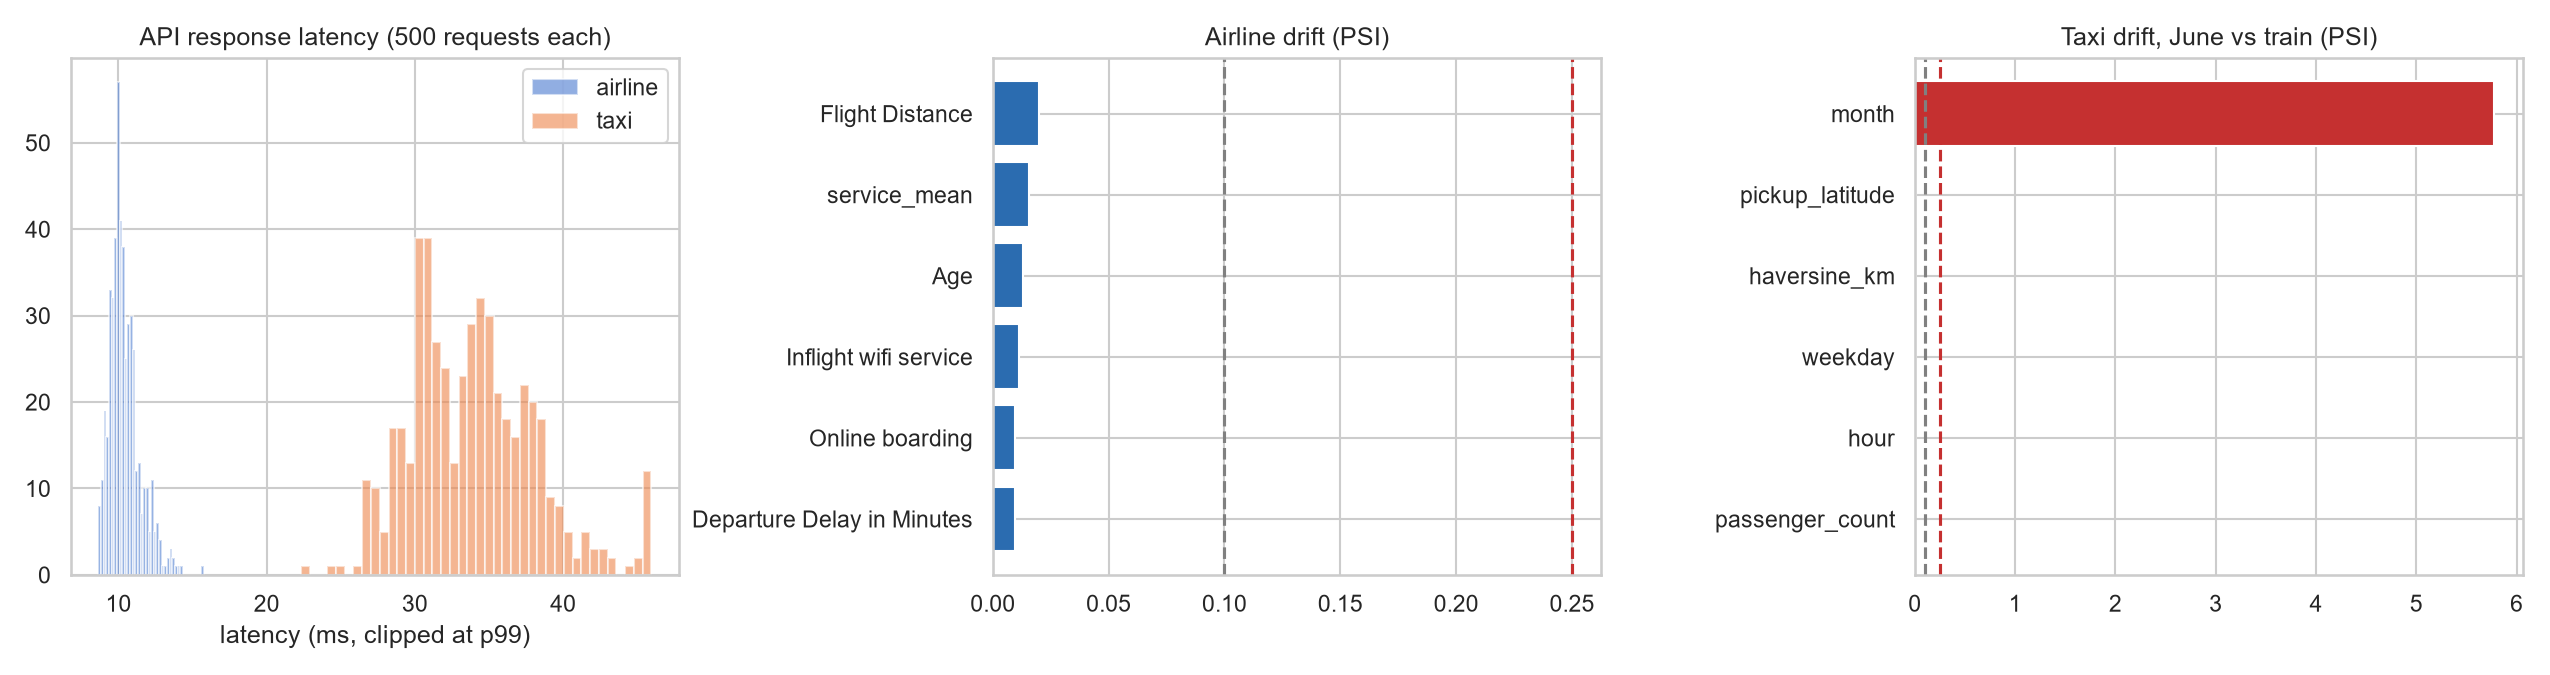

In [27]:
from IPython.display import Image
Image(filename=str(FIG / "monitoring_latency_drift.png"))

# 10. Summary of results

In [28]:
mon = json.loads((REPORTS / "monitoring.json").read_text())
summary = pd.DataFrame({
    "Airline (test)": {**air_report["test"]},
    "Taxi (test)": {**taxi_report["test"]},
}).T
display(summary)
print("Airline success criteria met:",
      air_report["test"]["accuracy"] >= 0.95 and air_report["test"]["f1"] >= 0.94 and air_report["test"]["roc_auc"] >= 0.98)
print("Taxi success criteria met:   ",
      taxi_report["test"]["rmsle"] <= 0.40 and taxi_report["test"]["r2_log"] >= 0.70)
print("Live monitoring:", mon["airline_live"], mon["taxi_live"])

,accuracy,precision,recall,f1,roc_auc,rmsle,r2_log,rmse_seconds,mae_seconds,median_ae_seconds,r2_seconds
Airline (test),0.9652,0.975,0.945,0.9598,0.9956,NaN,NaN,NaN,NaN,NaN,NaN
Taxi (test),NaN,NaN,NaN,NaN,NaN,0.2804,0.8508,260.6451,151.1311,94.1465,0.8421


Airline success criteria met: True
Taxi success criteria met:    True
Live monitoring: {'accuracy': 0.97, 'f1': 0.9657} {'rmsle': 0.2398, 'mae_seconds': 143.6}


Optionally, regenerate the numbers used by the LaTeX report (`report/metrics.tex`):

In [29]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT / "report" / "make_metrics.py")], capture_output=True, text=True, cwd=ROOT).stdout)

wrote 187 macros

